In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.optimize as opt

In [ ]:
# 1b
def G(phi, I, eps, I0=(1/(1-np.exp(-1)))):
    return I + eps*(np.sin(2*np.pi*phi) - 2*np.pi*np.cos(2*np.pi*phi))/(1+4*np.pi**2) - I0

I = 1.6
eps = 0.5

# solve for phi given I and eps
r1 = opt.root_scalar(G, bracket=[0, 0.5], args=(I, eps)).root
r2 = opt.root_scalar(G, bracket=[0.5, 1], args=(I, eps)).root

print(f"Roots of G(phi) for I={I} and eps={eps}:")
print(f"r1 = {r1:.3f}")
print(f"r2 = {r2:.3f}")

Roots of G(phi) for I=1.6 and eps=0.5:
r1 = 0.188
r2 = 0.762


In [ ]:
# 1c

eps = 0.5
I = np.linspace(0.9,3,100)
dt, T = 1e-4, 50
t_start = 0.2 * T  # discard initial 20% as transient
firing_nums = []
unforced_firing_nums = []

for I_val in I:
    t = np.arange(0, T, dt)
    v = np.zeros_like(t)
    spikes = []

    for k in range(len(t) - 1):
        v[k+1] = v[k] + dt * (-v[k] + I_val + eps*np.sin(2*np.pi*t[k]))

        if v[k+1] >= 1:
            v[k+1] = 0
            spikes.append(t[k+1])

    spikes = np.array(spikes)
    firing_nums.append(np.sum(spikes >= t_start) / (T - t_start))
    unforced_firing_nums.append(0 if I_val <= 1 else 1/np.log(I_val/(I_val-1)))

/var/folders/7c/hwzp1mjj72sbl2csmq_n0bn00000gn/T/ipykernel_34319/2675694786.py:24: RuntimeWarning: invalid value encountered in log
  unforced_firing_nums.append(1 / np.log(I_val/(I_val - 1)))


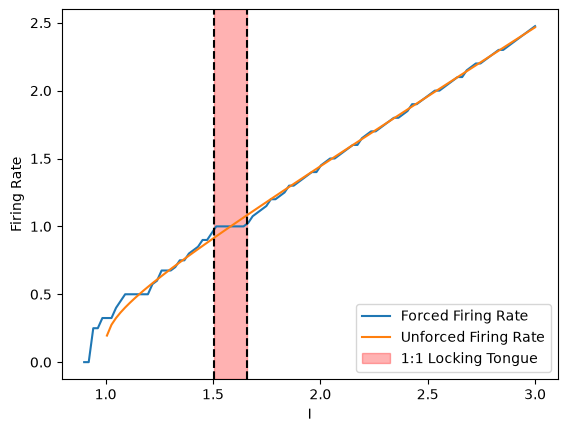

Phase at I=1.6: 0.188


In [21]:
plt.plot(I, firing_nums, label='Forced Firing Rate')
plt.plot(I, unforced_firing_nums, label='Unforced Firing Rate')
Il = -((eps/np.sqrt(1+4*np.pi**2))-1/(1-np.exp(-1)))
Ir = ((eps/np.sqrt(1+4*np.pi**2))+1/(1-np.exp(-1)))
plt.axvline(x=Il, color='k', linestyle='--')
plt.axvline(x=Ir, color='k', linestyle='--')
plt.axvspan(Il, Ir, alpha=0.3, color='red', label='1:1 Locking Tongue')
plt.xlabel('I'); plt.ylabel('Firing Rate')
plt.legend()
plt.show()

# simulate at I=1.6 and take spike phases after the transient
t = np.arange(0, T, dt)
v = np.zeros_like(t)
spikes = []
for k in range(len(t) - 1):
    v[k+1] = v[k] + dt * (-v[k] + 1.6 + eps*np.sin(2*np.pi*t[k]))
    if v[k+1] >= 1:
        v[k+1] = 0
        spikes.append(t[k+1])
spikes = np.array(spikes)
phases = spikes[spikes >= t_start] % 1

print(f"Phase at I=1.6: {phases.mean():.3f}")

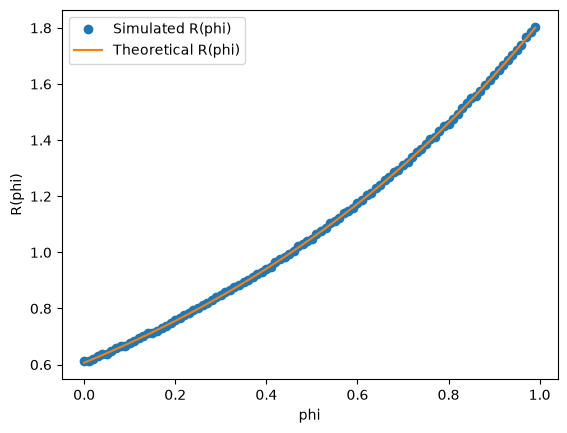

In [36]:
# 2c

# f = -v/tau
tau = 1
vr = 0
vth = 1
I = 1.5
D = tau * np.log((vr-tau*I)/(vth-tau*I))
dv = 1e-3
dt = 1e-5
phi = np.linspace(0, 0.99, 100)
Rs = []


def R(Tprime, D, dv):
    return (D - Tprime)/(D*dv)

for i in range(len(phi)):
    Tprime = 0
    t = []
    v = []
    kicked = False

    while True:
        v.append(v[-1] + dt * (-v[-1]/tau + I) if v else vr)
        t.append(t[-1] + dt if t else 0)

        if not kicked and np.abs(t[-1] - D*phi[i]) <= dt:
            v[-1] += dv
            kicked = True

        if v[-1] >= vth:
            Tprime = t[-1]
            Rs.append(R(Tprime, D, dv))
            break

        if t[-1] > 100:
            print("Simulation did not converge within 100 seconds.")
            break

def R_theory(phi, tau, D, I, vr):
    return (tau * np.exp((phi*D)/tau))/(D*(I*tau - vr))

plt.plot(phi, Rs, 'o', label='Simulated R(phi)')
plt.plot(phi, R_theory(phi, tau, D, I, vr), label='Theoretical R(phi)')
plt.xlabel('phi')
plt.ylabel('R(phi)')
plt.legend()
plt.show()

Period: 39.474
Max R = 0.286 at phi = 0.89
Min R = -0.117 at phi = 0.30


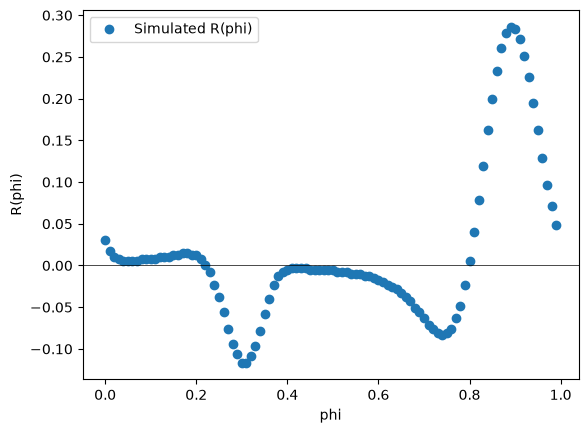

In [41]:
# Fitzhugh-Nagumo

def f(v, w):
    return v - v**3/3 - w + 0.5, 0.08*(v + 0.7 - 0.8*w)

dv = 1e-3
dt = 1e-4
n_cycles = 5  # number of cycles to measure the shift after perturbation
phi = np.linspace(0, 0.99, 100)
Rs = []

v, w, t = 0.0, 0.0, 0.0
crossings = []

# Simulate FH for 10 upward crossings
while len(crossings) < 10:
    dvdt, dwdt = f(v, w)
    v_new, w_new = v + dt*dvdt, w + dt*dwdt

    t += dt

    if v < 0 <= v_new:
        crossings.append(t)
    
    v, w = v_new, w_new

D = crossings[-1] - crossings[-2]  # period
v0, w0 = v, w

def nth_crossing(kick_time=None):
    v, w, t = v0, w0, 0.0
    kicked = False
    count = 0

    while True:
        if kick_time is not None and not kicked and t >= kick_time:
            v += dv
            kicked = True

        dvdt, dwdt = f(v, w)
        v_new, w_new = v + dt*dvdt, w + dt*dwdt

        if v < 0 <= v_new:
            count += 1
            if count == n_cycles:
                return t
            
        v, w = v_new, w_new
        t += dt

T0 = nth_crossing()  # unperturbed time of the 5th crossing

for i in range(len(phi)):
    Tprime = nth_crossing(D*phi[i])
    Rs.append((T0 - Tprime)/(D*dv))

Rs = np.array(Rs)

print(f"Period: {D:.3f}")
print(f"Max R = {Rs.max():.3f} at phi = {phi[Rs.argmax()]:.2f}")
print(f"Min R = {Rs.min():.3f} at phi = {phi[Rs.argmin()]:.2f}")

plt.plot(phi, Rs, 'o', label='Simulated R(phi)')
plt.axhline(0, color='k', linewidth=0.5)
plt.xlabel('phi')
plt.ylabel('R(phi)')
plt.legend()
plt.show()

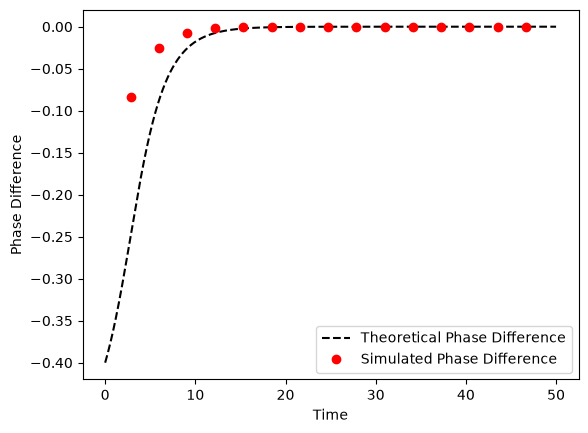

In [77]:
# 4c
def f(v1, v2, eps):
    return 1 + v1**2 + eps*(v2-v1), 1 + v2**2 + eps*(v1-v2)

dt, T = 1e-4, 50

t = np.arange(0, T, dt)
v1, v2 = np.zeros_like(t), np.zeros_like(t)
L = 200
phi0 = 0.4
eps = 0.2

def sim_gap_junction_QIF(v1, v2, eps, phi0, dt, T):
    def cot(x):
        return 1/np.tan(x)

    def arccot(x):
        return np.pi/2 - np.arctan(x)

    v1[0] = -200
    v2[0] = -cot(phi0*(arccot(-200) - arccot(200)))

    spikes1 = []
    spikes2 = []

    for k in range(len(t) - 1):
        v1[k+1] = v1[k] + dt * f(v1[k], v2[k], eps)[0]
        v2[k+1] = v2[k] + dt * f(v1[k], v2[k], eps)[1]

        if v1[k+1] >= L:
            v1[k+1] = -L
            spikes1.append(t[k+1])

        if v2[k+1] >= L:
            v2[k+1] = -L
            spikes2.append(t[k+1])

    spikes1 = np.array(spikes1)
    spikes2 = np.array(spikes2)
    max_spikes = min(len(spikes1), len(spikes2))
    spikes1 = spikes1[:max_spikes]
    spikes2 = spikes2[:max_spikes]
    phik = (spikes2[:-1] - spikes1[:-1]) / (spikes1[1:] - spikes1[:-1])

    def phi_theory(phi0, eps, t):
        return (1/np.pi) * np.arctan(np.tan(np.pi*phi0)*np.exp(-2*eps*t))

    phit = phi_theory(phi0, eps, t[1:])

    return spikes1, spikes2, phik, phit

spikes1, spikes2, phik, phit = sim_gap_junction_QIF(v1, v2, eps, phi0, dt, T)

plt.plot(t[1:], -phit, label='Theoretical Phase Difference', color='k', linestyle='--')
plt.plot(spikes1[:-1], phik, 'o', label='Simulated Phase Difference', color='r')
plt.xlabel('Time')
plt.ylabel('Phase Difference')
plt.legend()

In [ ]:
eps = [0.005, 0.02, 0.05]

for e in eps:
    spikes1, spikes2, phik, phit = sim_gap_junction_QIF(v1, v2, e, phi0, dt, T)

    # fit decay rate
    def decay_func(t, b):
        return np.tan(np.pi*phi0) * np.exp(-b * t)

    from scipy.optimize import curve_fit
    decay_rate, _ = curve_fit(decay_func, spikes1[:-1], np.tan(np.pi*-phik))
    print(f"Decay rate for eps={e}: {decay_rate}")
    

Decay rate for eps=0.005: [0.01277904]
Decay rate for eps=0.02: [0.05311086]
Decay rate for eps=0.05: [0.17333363]
